# Лабораторная работа №5
## Тема: Нейронные сети. Многослойный перцептрон (MLP)
**Датасет:** Stroke Prediction Dataset (Прогнозирование риска инсульта)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Нейросеть и классические модели
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Инструменты для подготовки данных и оценки
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, log_loss

# Настройки графиков
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Библиотеки успешно загружены! Готов к работе.")

Библиотеки успешно загружены! Готов к работе.


In [2]:
# 1. Загрузка данных
df = pd.read_csv('stroke_data.csv')

# 2. Очистка данных
# Удаляем столбец id (он не влияет на риск инсульта)
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Удаляем редкую категорию 'Other' в поле gender (чтобы не путать модель из-за 1 пациента)
df = df[df['gender'] != 'Other'].copy()

# Заполняем пропуски в 'bmi' медианой (используем безопасный метод без inplace=True)
median_bmi = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(median_bmi)

# 3. Преобразование категориальных признаков в числа (One-Hot Encoding)
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

# 4. Разделение на признаки (X) и целевую переменную (y)
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# 5. Разделение на обучающую и тестовую выборки (70% / 30%)
# stratify=y сохраняет правильную пропорцию больных и здоровых в обеих выборках
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 6. Масштабирование признаков (StandardScaler) — критически важно для нейросетей!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размер обучающей выборки: {X_train_scaled.shape} (строк, признаков)")
print(f"Размер тестовой выборки:  {X_test_scaled.shape} (строк, признаков)")
print(f"Количество входных нейронов в сети будет равно: {X_train_scaled.shape[1]}")

Размер обучающей выборки: (3576, 15) (строк, признаков)
Размер тестовой выборки:  (1533, 15) (строк, признаков)
Количество входных нейронов в сети будет равно: 15


Обучение нейросети запущено... (это займет пару секунд)
Обучение успешно завершено!

Итоговая точность MLP на тестовой выборке: 93.80%


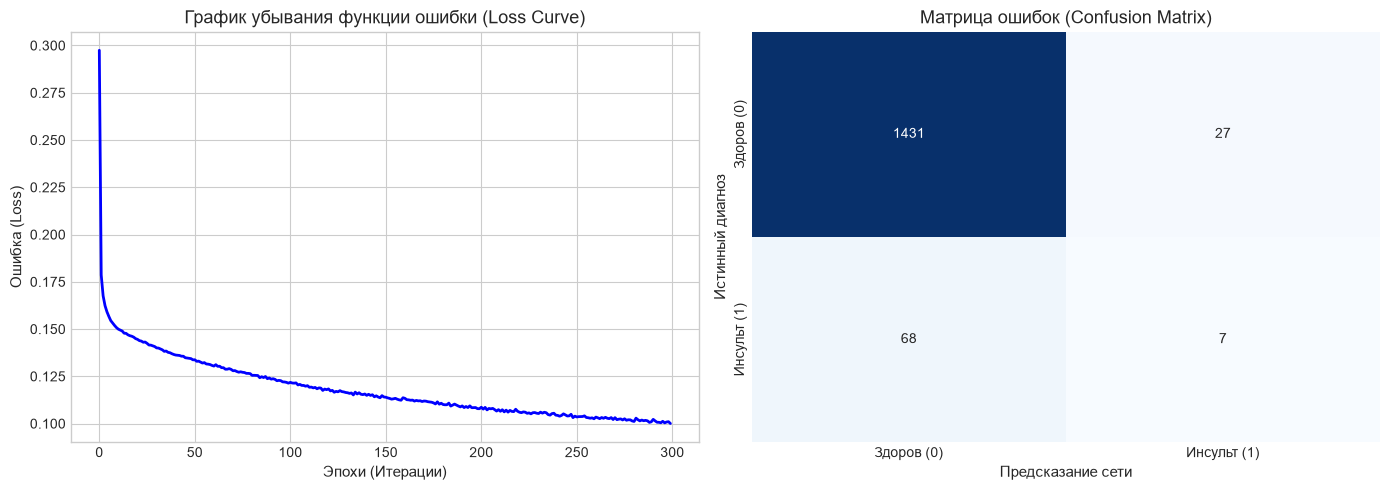

In [3]:
# -------------------------------------------------------------
# ШАГ 3: Создание и обучение нейронной сети (MLP)
# -------------------------------------------------------------
mlp_model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    batch_size=16,
    max_iter=300, # Увеличили лимит шагов, чтобы избежать предупреждений
    random_state=42
)

print("Обучение нейросети запущено... (это займет пару секунд)")
mlp_model.fit(X_train_scaled, y_train)
print("Обучение успешно завершено!")

# -------------------------------------------------------------
# ШАГ 4: Оценка модели и визуализация
# -------------------------------------------------------------
# Получаем предсказания на тестовых данных
y_pred_mlp = mlp_model.predict(X_test_scaled)
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)

print(f"\nИтоговая точность MLP на тестовой выборке: {mlp_accuracy * 100:.2f}%")

# Визуализация результатов (Графики)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Функция ошибки (Loss Curve) - как в методичке
axes[0].plot(mlp_model.loss_curve_, color='blue', lw=2)
axes[0].set_title('График убывания функции ошибки (Loss Curve)', fontsize=13)
axes[0].set_xlabel('Эпохи (Итерации)', fontsize=11)
axes[0].set_ylabel('Ошибка (Loss)', fontsize=11)
axes[0].grid(True)

# График 2: Матрица ошибок (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred_mlp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Здоров (0)', 'Инсульт (1)'],
            yticklabels=['Здоров (0)', 'Инсульт (1)'])
axes[1].set_title('Матрица ошибок (Confusion Matrix)', fontsize=13)
axes[1].set_xlabel('Предсказание сети', fontsize=11)
axes[1].set_ylabel('Истинный диагноз', fontsize=11)

plt.tight_layout()
plt.show()

--- ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ---
               Алгоритм  Точность (Accuracy)
Логистическая регрессия             0.952381
     Случайный лес (RF)             0.949772
        Нейросеть (MLP)             0.938030


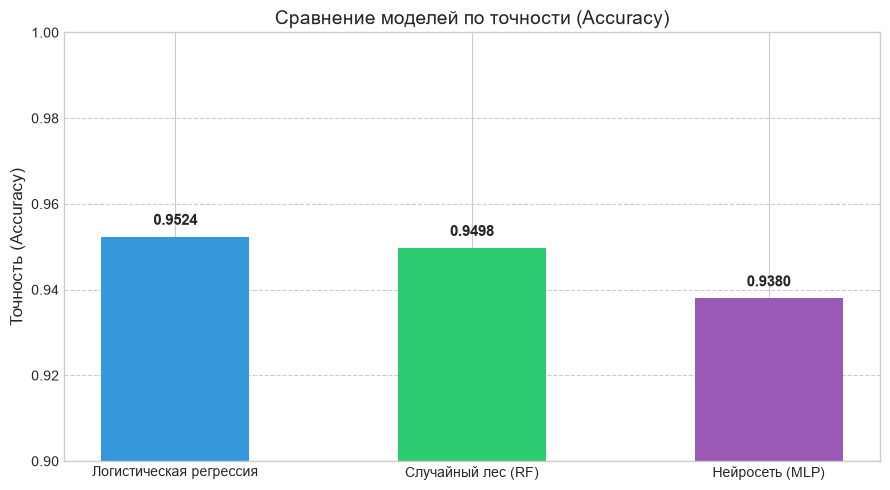

In [4]:
# -------------------------------------------------------------
# ШАГ 5: Сравнение с классическими алгоритмами
# -------------------------------------------------------------

# 1. Логистическая регрессия (Линейная модель)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_accuracy = accuracy_score(y_test, lr_model.predict(X_test_scaled))

# 2. Случайный лес (Ансамблевая модель)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_accuracy = accuracy_score(y_test, rf_model.predict(X_test_scaled))

# Создание сводной таблицы сравнения
comparison_df = pd.DataFrame({
    'Алгоритм': ['Логистическая регрессия', 'Случайный лес (RF)', 'Нейросеть (MLP)'],
    'Точность (Accuracy)': [lr_accuracy, rf_accuracy, mlp_accuracy]
})

print("--- ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ---")
print(comparison_df.to_string(index=False))

# Визуализация сравнения в виде столбчатой диаграммы
plt.figure(figsize=(9, 5))
colors = ['#3498db', '#2ecc71', '#9b59b6']
bars = plt.bar(comparison_df['Алгоритм'], comparison_df['Точность (Accuracy)'], color=colors, width=0.5)

plt.title('Сравнение моделей по точности (Accuracy)', fontsize=14)
plt.ylim(0.9, 1.0) # Задаем масштаб по Y (от 0.9 до 1.0), чтобы разница была заметнее
plt.ylabel('Точность (Accuracy)', fontsize=12)

# Добавляем текстовые подписи значений прямо над столбцами
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f"{yval:.4f}", 
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

Файлы dataIn.txt и dataOut.txt успешно созданы!
Точность предсказания выборов на тестовых избирателях: 50.00%


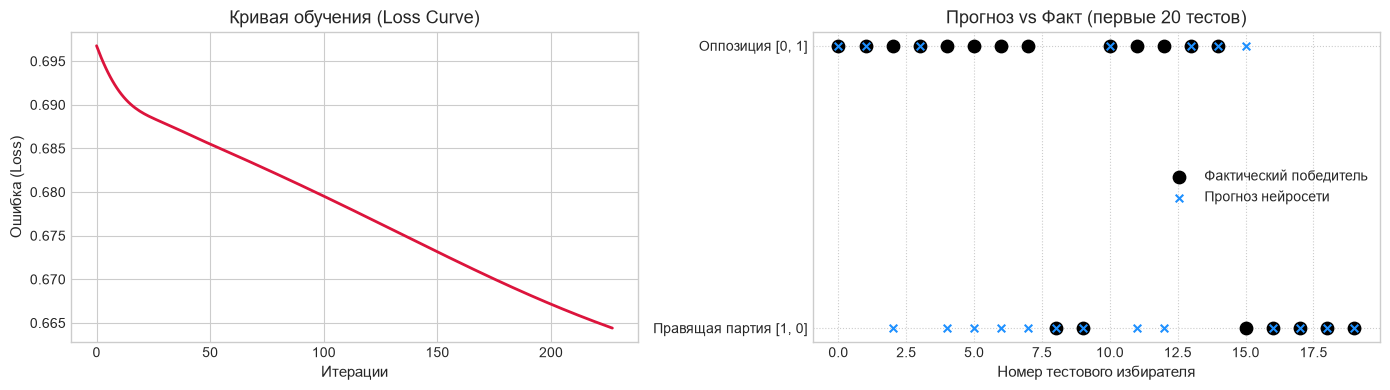

In [5]:
# =============================================================
# ЗАДАНИЕ "ВЫБОРЫ ПРЕЗИДЕНТА" (СТРАНИЦА 19 МЕТОДИЧКИ)
# =============================================================

# 1. Подготовка данных и запись в файлы
np.random.seed(42)
N_voters = 200 # Количество избирателей

# 12 бинарных ответов (0 - 'нет', 1 - 'да')
X_votes = np.random.randint(0, 2, size=(N_voters, 12))

# Исход выборов: [1, 0] - правящая партия, [0, 1] - оппозиция
true_winners = np.random.randint(0, 2, size=N_voters)
Y_votes = np.zeros((N_voters, 2), dtype=int)
Y_votes[np.arange(N_voters), true_winners] = 1 # Создаем правильный One-Hot Encoding

# Сохраняем строго по требованию методички
np.savetxt('dataIn.txt', X_votes, fmt='%d')
np.savetxt('dataOut.txt', Y_votes, fmt='%d')
print("Файлы dataIn.txt и dataOut.txt успешно созданы!")

# Считываем из файлов
X_loaded = np.loadtxt('dataIn.txt')
Y_loaded = np.loadtxt('dataOut.txt')

# Преобразуем One-Hot обратно в одномерный массив (0 и 1) для обучения в sklearn
y_labels = np.argmax(Y_loaded, axis=1)

# Разделение на train и test
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X_loaded, y_labels, test_size=0.25, random_state=42
)

# 2. Нейросеть с ОДНИМ скрытым слоем и функцией logsig (logistic)
model_elections = MLPClassifier(
    hidden_layer_sizes=(16,),      # Строго один скрытый слой
    activation='logistic',         # logsig — логистическая сигмоида
    solver='adam',
    max_iter=500,                  # Даем время на обучение
    random_state=42
)

# 3. Обучение модели
model_elections.fit(X_train_v, y_train_v)

# 4. Проверка точности на ТЕСТОВЫХ примерах
y_pred_v = model_elections.predict(X_test_v)
v_acc = accuracy_score(y_test_v, y_pred_v)
print(f"Точность предсказания выборов на тестовых избирателях: {v_acc * 100:.2f}%")

# 5. Визуализация результатов предсказаний
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# График 1: Убывание ошибки
axes[0].plot(model_elections.loss_curve_, color='crimson', lw=2)
axes[0].set_title('Кривая обучения (Loss Curve)', fontsize=13)
axes[0].set_xlabel('Итерации', fontsize=11)
axes[0].set_ylabel('Ошибка (Loss)', fontsize=11)
axes[0].grid(True)

# График 2: Сравнение факта и предсказания для первых 20 человек
sample_ids = np.arange(20)
axes[1].scatter(sample_ids, y_test_v[:20], color='black', label='Фактический победитель', s=80, marker='o')
axes[1].scatter(sample_ids, y_pred_v[:20], color='dodgerblue', label='Прогноз нейросети', s=30, marker='x')
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(['Правящая партия [1, 0]', 'Оппозиция [0, 1]'])
axes[1].set_title('Прогноз vs Факт (первые 20 тестов)', fontsize=13)
axes[1].set_xlabel('Номер тестового избирателя', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle=':')

plt.tight_layout()
plt.show()